# Test: CCF of the disc-integrated spectrum vs CCF mode (raw CCFs)

The quiet Sun computed in two ways, which should give the same CCF:

1. **Spectrum first.** The spectrum of every cell of the disc (MURaM high resolution spectra interpolated at the μ of the cell and Doppler shifted by its rotation velocity: `flux_grid(..., mode='spectroscopy', stellar_rotation=True)`), summed into the **disc-integrated spectrum**, whose CCF is computed with the line mask.
2. **CCF mode.** The same spectra in `CCF_grid`: the CCF of the spectrum of every ring (rest frame), then `StarSim(mode=['ccf'])` shifts the CCF of every cell by its rotation velocity and adds them.

**All the CCFs are raw** (`normalization='none'`): the CCF is minus the mask-weighted sum of the fluxes, in the units of the spectra, never normalised or rescaled. The CCF is linear in the spectrum, so the raw CCF of every ring keeps the brightness of the ring at every line (limb darkening, at every wavelength), and both paths weight a cell by its projected area / 4π: the two CCFs can be compared directly, without any weight or factor.

Full MURaM spectrum (3800-8000 Å, all the lines of the HARPS G2 mask inside it), 10 rings, the Sun: equatorial period 24.47 d, solar differential rotation, inclination 7.25°, 1 R☉.

In [1]:
import os
os.environ.setdefault('KMP_WARNINGS', '0')
import time
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sunsim import StarSim, SOLAR_DIFFERENTIAL_ROTATION, flux_grid, CCF_grid, mask_weights, nbspectra

# star: the Sun
rotation_period = 24.47                         # [days] at the equator
differential_rotation = SOLAR_DIFFERENTIAL_ROTATION
inclination = np.deg2rad(7.25)                  # [rad] (0 = equator-on)
stellar_radius = 1.0                            # [solar radii]
N_rings = 10                                    # the spectra of the ~230 cells of the whole spectrum take ~0.8 GB
RAW = 2                                         # nbspectra.cross_correlation_mask: no normalisation

# MURaM high resolution spectra of the quiet Sun at 10 mu: the full spectrum
muram_file = ('/Users/sophiestucki/Library/CloudStorage/GoogleDrive-stucki@ieec.cat/Shared drives/Exoplanets-Group/'
              'MPS-ATLAS spectra/av_solar_ssd_200G_10_mu_angles_PHOENIX_high_res_grid.npy')
raw = np.load(muram_file, allow_pickle=True).item()
spectra = {float(mu): {'wav': np.asarray(d['wav'], dtype=np.float64), 'intensity': np.asarray(d['intensity'], dtype=np.float64)}
           for mu, d in raw.items()}
del raw
wav = spectra[1.0]['wav']

# all the mask lines inside the spectrum (with a margin of 1 A for the Doppler shifts), velocity grid
wvm_all, fm_all = mask_weights('/Users/sophiestucki/starsim/starsim/masks/HARPS_G20_mps_friendly.mas')
keep = (wvm_all > wav[0] + 1) & (wvm_all < wav[-1] - 1)
wvm, fm = wvm_all[keep], fm_all[keep]
rv = 1000 * np.arange(-20, 20.25, 0.25)        # [m/s]
vsini = 2 * np.pi * stellar_radius * 6.957e8 / (rotation_period * 86400) * np.cos(inclination)
print('%d mu angles, %d wavelengths (%.0f-%.0f A), %d mask lines; vsini = %.0f m/s'
      % (len(spectra), len(wav), wav[0], wav[-1], len(wvm), vsini))

10 mu angles, 499998 wavelengths (3800-8000 A), 3492 mask lines; vsini = 2051 m/s


## 1. Spectrum first: disc-integrated spectrum, then its raw CCF

In [2]:
def disc_spectrum(rotation, spec=None):
    # disc-integrated spectrum: sum of the spectra of all the cells (Doppler shifted if rotation), whole spectrum
    spec = spectra if spec is None else spec
    w = spec[1.0]['wav']
    g = flux_grid(N_rings, spec, 'quiet', None, w[0], w[-1], rotation_period=rotation_period, inclination=inclination,
                  stellar_radius=stellar_radius, stellar_rotation=rotation, mode='spectroscopy',
                  differential_rotation=differential_rotation)
    g.built_grid()
    out = g.wv, g.grid.sum(axis=0)              # wavelengths (shortened at both ends with rotation), spectrum
    del g
    return out

t0 = time.perf_counter()
disc = {'rotation': disc_spectrum(True), 'no rotation': disc_spectrum(False)}
ccf_spectrum = {k: nbspectra.cross_correlation_mask(rv, w, f, wvm, fm, False, RAW) for k, (w, f) in disc.items()}
print('disc-integrated spectra and their CCFs: %.1f s' % (time.perf_counter() - t0))

disc-integrated spectra and their CCFs: 13.6 s


## 2. CCF mode with the same spectra (raw CCFs)

`CCF_grid(..., normalization='none')` with the 10 spectra and no `mu_ratio`: the spectrum of every ring is interpolated at its μ (`interpolation='spectrum'`, as `flux_grid` does) and its raw CCF computed, so the brightness of every ring at every line is in its CCF. No bisector is added. Then `StarSim(mode=['ccf'])` with the same star, no active region, one epoch.

In [3]:
def ccf_mode(rotation, interpolation='spectrum', spec=None, rvs=rv):
    spec = spectra if spec is None else spec
    g = CCF_grid(N_rings, spec, rvs, wvm, fm, normalization='none', interpolation=interpolation)
    g.built_grid(bisector=None)
    ss = StarSim(np.array([0.0]), N_rings, inclination=inclination,
                 rotation_period=rotation_period if rotation else 1e12,     # no rotation: an extremely long period
                 differential_rotation=differential_rotation if rotation else 0, stellar_radius=stellar_radius,
                 active_regions_map=[], mode=['ccf'], ccf_grid_qp=g, ccf_grid_sp=g, ccf_grid_fc=g)
    ss.generate_timeseries(verbose=False)
    return ss

t0 = time.perf_counter()
runs = {'rotation': ccf_mode(True), 'no rotation': ccf_mode(False), "rotation, interpolation='ccf'": ccf_mode(True, 'ccf')}
ccf_ccfmode = {k: ss.ccf_var[0] for k, ss in runs.items()}
print('CCF mode: %.1f s' % (time.perf_counter() - t0))

CCF mode: 25.1 s


## 3. Comparison of the raw CCFs and of their bisectors

The raw CCFs are compared as they are (the same units, no rescaling). RV, FWHM, contrast and BIS are measured with the same fit (`StarSim.compute_ccf_params`, a gaussian with a free offset, and the bisector) on the raw CCFs.

In [4]:
fitter = runs['rotation']
pairs = {'rotation': ('rotation', 'rotation'), 'no rotation': ('no rotation', 'no rotation'),
         "rotation, CCF mode with interpolation='ccf'": ('rotation', "rotation, interpolation='ccf'")}
rows, fits = [], {}
for name, (ks, kc) in pairs.items():
    a, c = ccf_spectrum[ks], ccf_ccfmode[kc]
    fits[name] = fitter.compute_ccf_params(rv=rv, ccf=[a, c])
    r, contrast, fwhm, BIS = fits[name][:4]
    for k, label in enumerate(('spectrum first', 'CCF mode')):
        rows.append({'case': name, 'method': label, 'RV [m/s]': r[k], 'FWHM [m/s]': fwhm[k], 'contrast': contrast[k],
                     'BIS [m/s]': BIS[k]})
    rows.append({'case': name, 'method': 'difference', 'RV [m/s]': r[1] - r[0], 'FWHM [m/s]': fwhm[1] - fwhm[0],
                 'contrast': contrast[1] - contrast[0], 'BIS [m/s]': BIS[1] - BIS[0],
                 'max |CCF difference| / depth of the CCF': np.max(np.abs(c - a)) / np.ptp(a)})
pd.options.display.float_format = '{:.5g}'.format
pd.DataFrame(rows).set_index(['case', 'method'])

RV [m/s]  \
case                                        method                      
rotation                                    spectrum first    -983.97   
                                            CCF mode          -983.93   
                                            difference       0.048356   
no rotation                                 spectrum first    -978.07   
                                            CCF mode          -978.07   
                                            difference     2.7304e-09   
rotation, CCF mode with interpolation='ccf' spectrum first    -983.97   
                                            CCF mode          -983.34   
                                            difference        0.63795   

                                                            FWHM [m/s]  \
case                                        method                       
rotation                                    spectrum first      6866.6   
                                            CCF mode            6857.7   
                                            difference         -8.9382   
no rotation                                 spectrum first      6554.1   
                                            CCF mode            6554.1   
                                            difference      1.1491e-08   
rotation, CCF mode with interpolation='ccf' spectrum first      6866.6   
                                            CCF mode            6859.1   
                                            difference         -7.5329   

                                                              contrast  \
case                                        method                       
rotation                                    spectrum first   0.0036859   
                                            CCF mode          0.003691   
                                            difference      5.0784e-06   
no rotation                                 spectrum first   0.0038931   
                                            CCF mode         0.0038931   
                                            difference     -9.5019e-16   
rotation, CCF mode with interpolation='ccf' spectrum first   0.0036859   
                                            CCF mode         0.0036965   
                                            difference       1.058e-05   

                                                            BIS [m/s]  \
case                                        method                      
rotation                                    spectrum first    -44.905   
                                            CCF mode          -45.085   
                                            difference       -0.17988   
no rotation                                 spectrum first    -58.904   
                                            CCF mode          -58.904   
                                            difference     9.5838e-11   
rotation, CCF mode with interpolation='ccf' spectrum first    -44.905   
                                            CCF mode          -44.858   
                                            difference       0.047649   

                                                            max |CCF difference| / depth of the CCF  
case                                        method                                                   
rotation                                    spectrum first                                      NaN  
                                            CCF mode                                            NaN  
                                            difference                                    0.0013581  
no rotation                                 spectrum first                                      NaN  
                                            CCF mode                                            NaN  
                                            difference                                   2.8711e-13  
rotatio

## 4. With rotation: the interpolation of the Doppler shifts

The rotation velocities of the cells are the same in both paths (`flux_grid.vrel` = `StarSim.rvel`), but the Doppler shift of every cell is a **linear interpolation**: of the spectrum in (1), on the MURaM grid (0.01 Å, 0.0060 Å below 5000 Å), and of the CCF in (2), on the velocity grid (250 m/s). A linear interpolation at a fraction of a pixel smooths the profile (it adds ~h²/6 to its variance, h = step). The check refines the two grids: the spectra resampled at 0.005 Å (cubic spline, for both paths) and the velocity grid at 250 and 50 m/s.

In [5]:
from scipy.interpolate import CubicSpline

def resampled(step):
    # the spectra on a finer wavelength grid (cubic spline), the same for the two paths
    new = np.arange(wav[0], wav[-1], step)
    return {mu: {'wav': new, 'intensity': CubicSpline(d['wav'], d['intensity'])(new)} for mu, d in spectra.items()}

rows = []
for step_label, spec in (('MURaM grid', spectra), ('0.005 A (cubic spline)', resampled(0.005))):
    w_disc, f_disc = disc_spectrum(True, spec)
    for rv_step in (250, 50):
        rvs = np.arange(-20000, 20000 + rv_step, rv_step)
        a = nbspectra.cross_correlation_mask(rvs, w_disc, f_disc, wvm, fm, False, RAW)
        c = ccf_mode(True, spec=spec, rvs=rvs).ccf_var[0]
        r, contrast, fwhm, BIS, _, _ = fitter.compute_ccf_params(rv=rvs, ccf=[a, c])
        rows.append({'spectrum step': step_label, 'velocity step [m/s]': rv_step, 'FWHM spectrum first [m/s]': fwhm[0],
                     'FWHM difference [m/s]': fwhm[1] - fwhm[0], 'RV difference [m/s]': r[1] - r[0],
                     'BIS difference [m/s]': BIS[1] - BIS[0]})
pd.options.display.float_format = '{:.4g}'.format
pd.DataFrame(rows).set_index(['spectrum step', 'velocity step [m/s]'])

FWHM spectrum first [m/s]  \
spectrum step          velocity step [m/s]                              
MURaM grid             250                                       6867   
                       50                                        6869   
0.005 A (cubic spline) 250                                       6851   
                       50                                        6854   

                                            FWHM difference [m/s]  \
spectrum step          velocity step [m/s]                          
MURaM grid             250                                 -8.938   
                       50                                  -12.75   
0.005 A (cubic spline) 250                                 -1.428   
                       50                                  -5.195   

                                            RV difference [m/s]  \
spectrum step          velocity step [m/s]                        
MURaM grid             250                              0.04836   
                       50                               0.09412   
0.005 A (cubic spline) 250                              0.04728   
                       50                               0.08304   

                                            BIS difference [m/s]  
spectrum step          velocity step [m/s]                        
MURaM grid             250                               -0.1799  
                       50                                -0.3005  
0.005 A (cubic spline) 250                               -0.1025  
                       50                                 -0.196

## Final figure: raw CCF and bisector with rotation

The quiet Sun with solar rotation: the raw CCF of the disc-integrated spectrum and the raw CCF of the CCF mode (as computed: same units, nothing rescaled), their difference, and their bisectors.

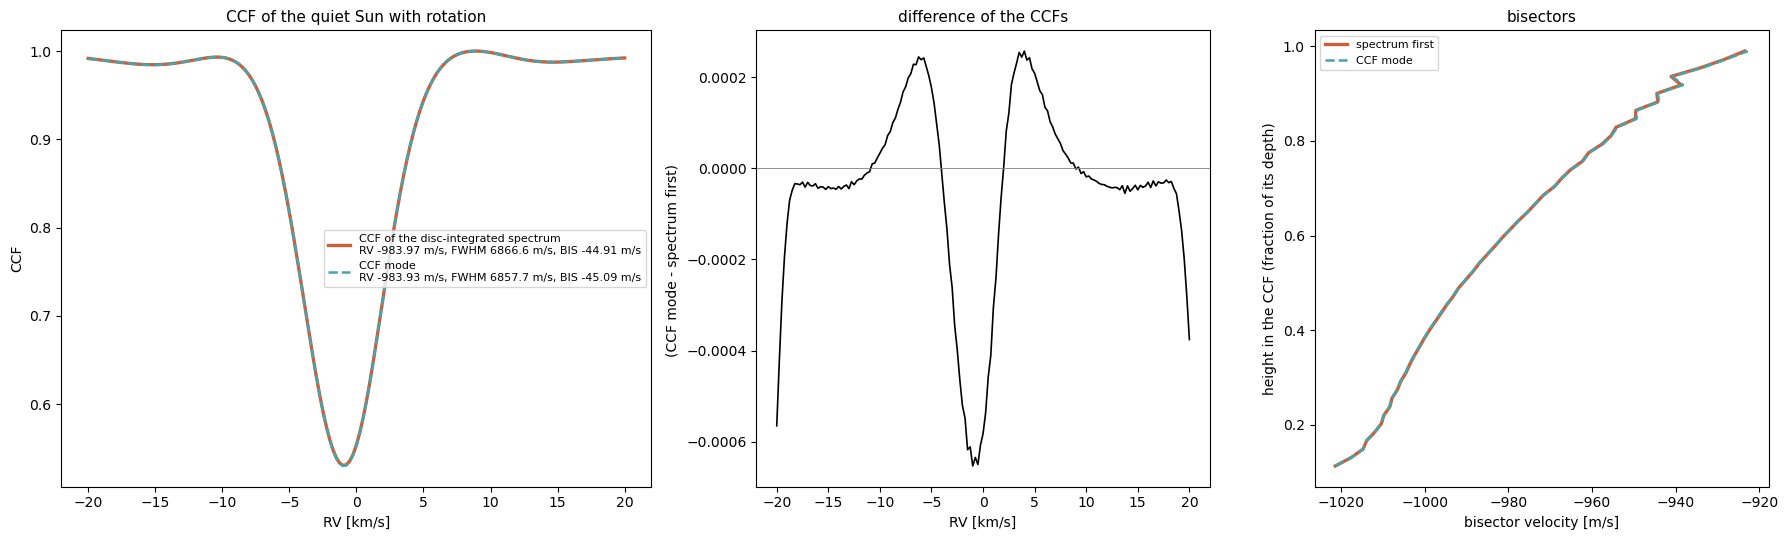

In [13]:
a, c = ccf_spectrum['rotation'], ccf_ccfmode['rotation']
r, contrast, fwhm, BIS, xbis, ybis = fits['rotation']
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), gridspec_kw={'width_ratios': [1.3, 1, 1]})
ax = axes[0]
ax.plot(rv / 1000, a/np.min(a), '-', lw=2.4, color='#cf5d3a',
        label='CCF of the disc-integrated spectrum\nRV %.2f m/s, FWHM %.1f m/s, BIS %.2f m/s' % (r[0], fwhm[0], BIS[0]))
ax.plot(rv / 1000, c/np.min(c), '--', lw=1.8, color='#45a5aa',
        label='CCF mode\nRV %.2f m/s, FWHM %.1f m/s, BIS %.2f m/s' % (r[1], fwhm[1], BIS[1]))
ax.set_xlabel('RV [km/s]')
ax.set_ylabel('CCF')
ax.set_title('CCF of the quiet Sun with rotation', fontsize=11)
ax.legend(fontsize=8)
ax = axes[1]
ax.plot(rv / 1000, (c/np.min(c) - a/np.min(a)), '-', color='k', lw=1.2)
ax.axhline(0, color='grey', lw=0.6)
ax.set_xlabel('RV [km/s]')
ax.set_ylabel('(CCF mode - spectrum first) ')
ax.set_title('difference of the CCFs', fontsize=11)
ax = axes[2]
ax.plot(xbis[0], ybis[0], '-', lw=2.4, color='#cf5d3a', label='spectrum first')
ax.plot(xbis[1], ybis[1], '--', lw=1.8, color='#45a5aa', label='CCF mode')
ax.set_xlabel('bisector velocity [m/s]')
ax.set_ylabel('height in the CCF (fraction of its depth)')
ax.set_title('bisectors', fontsize=11)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## Conclusions (raw CCFs, full spectrum, 10 rings)

* **Without rotation the two paths are identical** to the rounding: the raw CCFs differ by 3e-13 of their depth (RV 3e-9 m/s, FWHM 1e-8 m/s, BIS 1e-10 m/s). The CCF is linear in the spectrum, so the CCF mode with raw CCFs (`normalization='none'`) is exactly the CCF of the disc-integrated spectrum: the brightness of every ring at every line (the limb darkening, which depends on the wavelength) is in its raw CCF, with no weight to choose.
* **With rotation** (vsini 2.05 km/s, solar differential rotation): RV within 0.05 m/s, BIS within 0.18 m/s, the bisectors on top of each other, the raw CCFs within 0.14 % of their depth, and the CCF mode 8.9 m/s narrower in FWHM (0.13 %). The rotation velocities of the cells are the same in both paths; the difference is the linear interpolation of the Doppler shifts, which widens the spectra of the cells (sampled at 0.006-0.01 Å) in the spectrum-first path more than the CCFs (250 m/s) in the CCF mode: with the spectra resampled at 0.005 Å it falls to 1.4 m/s (section 4). The CCF mode is the more accurate here. Near the ends of the velocity grid (±20 km/s) the CCF mode extends the shifted ring CCFs with their end values (edge of the difference plot).
* `interpolation='ccf'` (the raw CCFs of the 10 tabulated spectra interpolated in μ, instead of the spectrum of every ring) moves the RV by 0.6 m/s here: interpolating the CCF linearly in μ is not exactly the CCF of the spectrum interpolated in μ when the lines change with μ.